# Features Extraction

In this notebook we examine several features that can be extracted from the original LOB dataset.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_ROOT = '../Data/FI-2010-Cleaned/NoAuctionMinMax/'

In [2]:
df = pd.read_parquet(DATA_ROOT + 'KESBV_NoAuction_MinMax.parquet')

### Mid Price and Weighted Mid Price

$$
\begin{align*}
    p_{mid} &= \frac{p_{ask}^{(1)} + p_{bid}^{(1)}}{2} \\
    p_{wmid} &= \frac{p_{ask}^{(1)} \cdot v_{ask}^{(1)} + p_{bid}^{(1)} \cdot v_{bid}^{(1)}}{v_{ask}^{(1)} + v_{bid}^{(1)}}
\end{align*}
$$

In [3]:
mid_price = lambda p_ask, p_bid: (p_ask + p_bid) / 2
wmid_price = lambda p_ask, p_bid, v_ask, v_bid: (p_ask * v_ask + p_bid * v_bid) / (v_ask + v_bid)

df['P_mid'] = mid_price(df['P_Ask_1'], df['P_Bid_1'])
df['P_wmid'] = wmid_price(df['P_Ask_1'], df['P_Bid_1'], df['V_Ask_1'], df['V_Bid_1'])

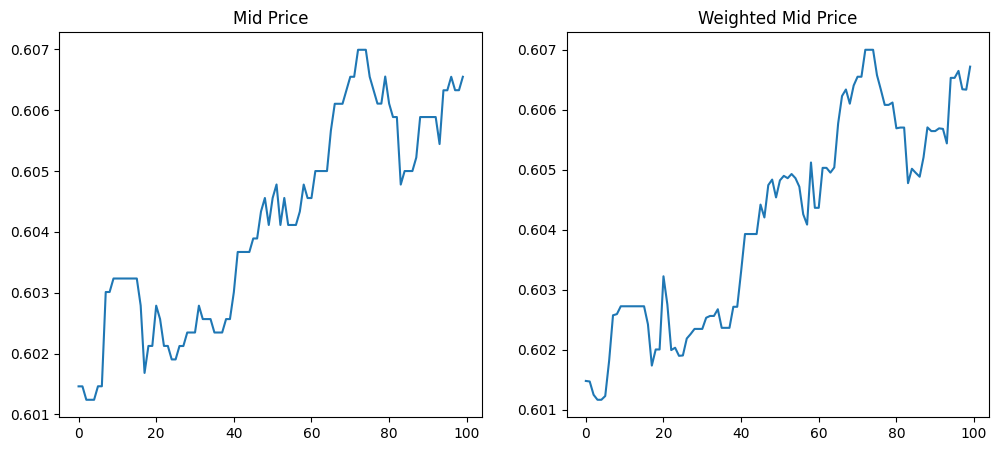

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].plot(df['P_mid'].head(100))
ax[0].set_title('Mid Price')
ax[1].plot(df['P_wmid'].head(100))
ax[1].set_title('Weighted Mid Price')
plt.show()

### Bid-Ask Spread

$$
\text{spread} = p_{ask}^{(1)} - p_{bid}^{(1)}
$$

In [5]:
lambda bid, ask: bid - ask

df['Spread'] = df['P_Ask_1'] - df['P_Bid_1']

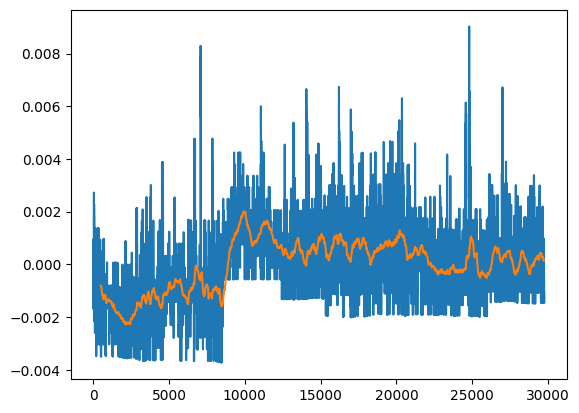

In [6]:
plt.plot(df['Spread'])
plt.plot(df['Spread'].rolling(window=500).mean())
plt.show()

### Order Book Imbalance

$$
\text{imbalance} = \frac{v_{ask}^{(1)} - v_{bid}^{(1)}}{v_{ask}^{(1)} + v_{bid}^{(1)}}
$$

In [7]:
imbalance_1 = lambda v_ask, v_bid: (v_ask - v_bid) / (v_ask + v_bid)

df['Imbalance_1'] = imbalance_1(df['V_Ask_1'], df['V_Bid_1'])

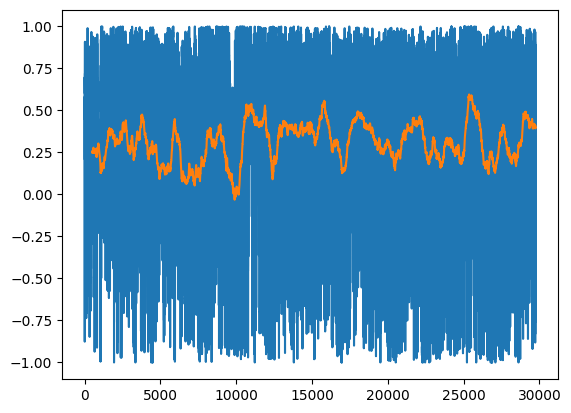

In [8]:
plt.plot(df['Imbalance_1'])
plt.plot(df['Imbalance_1'].rolling(500).mean())
plt.show()

### LOB Depth

$$
\begin{align*}
    \text{depth}_{ask} &= \sum_{i=1}^{10} v_{ask}^{(i)} \\
    \text{depth}_{bid} &= \sum_{i=1}^{10} v_{bid}^{(i)} \\
    \text{depth} &= \text{depth}_{ask} + \text{depth}_{bid}
\end{align*}
$$

In [9]:
depth_bid = lambda v_bid_df: v_bid_df.sum(axis=1)
depth_ask = lambda v_ask_df: v_ask_df.sum(axis=1)
depth = lambda depth_bid, depth_ask: depth_bid + depth_ask

df['Depth_Bid'] = depth_bid(df.filter(regex='V_Bid'))
df['Depth_Ask'] = depth_ask(df.filter(regex='V_Ask'))
df['Depth'] = depth(df['Depth_Bid'], df['Depth_Ask'])

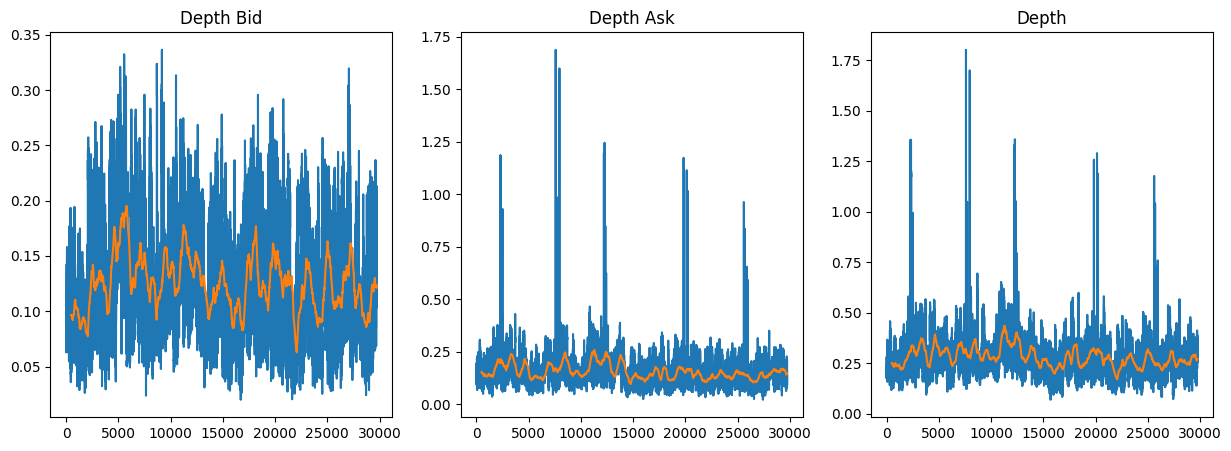

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].plot(df['Depth_Bid'])
ax[0].plot(df['Depth_Bid'].rolling(500).mean())
ax[0].set_title('Depth Bid')
ax[1].plot(df['Depth_Ask'])
ax[1].plot(df['Depth_Ask'].rolling(500).mean())
ax[1].set_title('Depth Ask')
ax[2].plot(df['Depth'])
ax[2].plot(df['Depth'].rolling(500).mean())
ax[2].set_title('Depth')
plt.show()

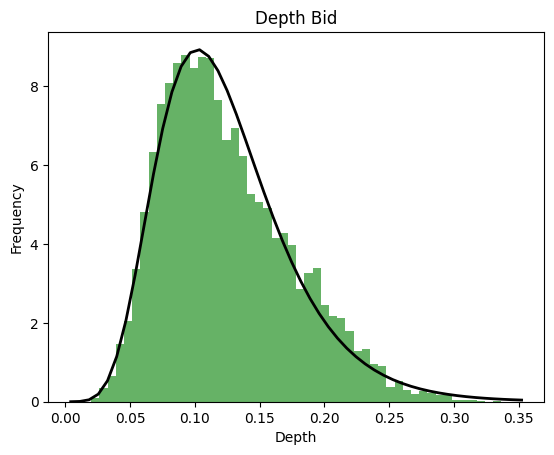

In [11]:
sample = df['Depth_Bid'].values

# Fit lognormal
from scipy.stats import lognorm

shape, loc, scale = lognorm.fit(sample)

# Plot the histogram.
plt.hist(sample, bins=50, density=True, alpha=0.6, color='g')
plt.title('Depth Bid')
plt.xlabel('Depth')
plt.ylabel('Frequency')

# Plot the PDF.
xmin, xmax = plt.xlim()
x = np.linspace(xmin, xmax, 50)
p = lognorm.pdf(x, shape, loc=loc, scale=scale)
plt.plot(x, p, 'k', linewidth=2)
plt.show()